# Project: Impacts of Meteorological Factors and Air Quality on Shared-Bicycle Usage in Seoul
## Research Question
How do meteorological variables including temperature, humidity and rainfall, together with PM2.5 and PM10 concentrations, affect the hourly rental volume of shared bicycles in Seoul?

### Dataset
- Seoul Bike Sharing Demand Dataset (UCI ML Repository)
- Seoul hourly air quality open dataset (Seoul Open Data Portal)
Time range: 2017–2018

### Tools
Python, Pandas, Matplotlib, Seaborn, Scikit-learn Linear Regression


In [1]:
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

D:\APP\Anaconda\lib\site-packages\scipy\__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.5
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


处理单车数据集

In [2]:
# 1. 读取数据
df_bike = pd.read_csv('SeoulBikeData.csv', encoding='cp949') 

In [3]:
# 2. 查看单车数据的列名
print("重命名前的列名：")
print(df_bike.columns.tolist())

重命名前的列名：
['Date', 'Rented Bike Count', 'Hour', 'Temperature(캜)', 'Humidity(%)', 'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(캜)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons', 'Holiday', 'Functioning Day']


In [4]:
# 3. 重命名
rename_dict = {
    'Temperature(캜)': 'Temperature_℃',
    'Humidity(%)': 'Humidity_%',
    'Wind speed (m/s)': 'Wind_speed_m/s',
    'Visibility (10m)': 'Visibility_10m',
    'Dew point temperature(캜)': 'Dew_point_temperature_℃',
    'Solar Radiation (MJ/m2)': 'Solar_Radiation_MJ/m2',
    'Rainfall(mm)': 'Rainfall_mm',
    'Snowfall (cm)': 'Snowfall_cm',
    'Rented Bike Count': 'Rented_Bike_Count'
}
df_bike.rename(columns=rename_dict, inplace=True)
df_bike.columns.tolist()

['Date',
 'Rented_Bike_Count',
 'Hour',
 'Temperature_℃',
 'Humidity_%',
 'Wind_speed_m/s',
 'Visibility_10m',
 'Dew_point_temperature_℃',
 'Solar_Radiation_MJ/m2',
 'Rainfall_mm',
 'Snowfall_cm',
 'Seasons',
 'Holiday',
 'Functioning Day']

In [5]:
# 2. 统一日期格式（原数据是 01/12/2017，日/月/年）
df_bike['Date'] = pd.to_datetime(df_bike['Date'], format='%d/%m/%Y')

In [6]:
print(df_bike.shape)
df_bike.head(3)

(8760, 14)


,Date,Rented_Bike_Count,Hour,Temperature_℃,Humidity_%,Wind_speed_m/s,Visibility_10m,Dew_point_temperature_℃,Solar_Radiation_MJ/m2,Rainfall_mm,Snowfall_cm,Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes


处理空气质量数据集

In [7]:
# 定义一个读取函数，自动尝试不同的编码
def read_korean_csv(filepath):
    encodings = ['cp949', 'euc-kr', 'utf-8', 'utf-8-sig', 'latin1']
    for enc in encodings:
        try:
            df = pd.read_csv(filepath, encoding=enc)
            print(f"成功！{filepath} 使用的编码是: {enc}")
            return df
        except UnicodeDecodeError:
            continue
    raise Exception(f"无法读取 {filepath}，请检查文件格式")

# 1。导入数据
df_air_2017 = read_korean_csv('AIR_HOUR_2017.csv')
df_air_2018 = read_korean_csv('AIR_HOUR_2018.csv')

成功！AIR_HOUR_2017.csv 使用的编码是: utf-8
成功！AIR_HOUR_2018.csv 使用的编码是: utf-8


In [8]:
# 2. 垂直拼接两年数据
df_air = pd.concat([df_air_2017, df_air_2018], ignore_index=True)

In [9]:
# 3. 将韩文列名翻译成英文
column_mapping = {
    '측정일시': 'Datetime',          # 测量日期时间 (例如 2018010100)
    '측정소 코드': 'Station_Code',   # 测量站代码 (例如 101)
    '측정항목': 'Pollutant_Code',    # 测量项目 (8=PM10, 9=PM2.5)
    '평균값': 'Value',                # 平均值 (浓度数值)
    '측정기 상태': 'Instrument_Status' # 仪器状态 (0=正常)
   }
df_air.rename(columns=column_mapping, inplace=True)

In [10]:
# 打印一下翻译后的列名
print("翻译后的空气数据列名：", df_air.columns.tolist())

翻译后的空气数据列名： ['Datetime', 'Station_Code', 'Pollutant_Code', 'Value', 'Instrument_Status', '국가 기준초과 구분', '지자체 기준초과 구분']


In [11]:
# 4. 保留仪器状态为正常的数据
df_air['Instrument_Status'] = pd.to_numeric(df_air['Instrument_Status'], errors='coerce')
df_air = df_air[df_air['Instrument_Status'] == 0]

In [12]:
# 5. 筛选 PM10 (8) 和 PM2.5 (9)
df_pm = df_air[df_air['Pollutant_Code'].isin([8, 9])].copy()

In [13]:
# 5. 长转宽（使用翻译后的英文列名）
df_pivot = df_pm.pivot_table(
    index=['Datetime', 'Station_Code'], 
    columns='Pollutant_Code', 
    values='Value'
).reset_index()
df_pivot.columns.name = None
df_pivot

,Datetime,Station_Code,8,9
0,2017010100,101,73.0,57.0
1,2017010100,102,77.0,63.0
2,2017010100,103,70.0,68.0
3,2017010100,104,73.0,46.0
4,2017010100,105,81.0,44.0
...,...,...,...,...
430193,2018123123,121,36.0,24.0
430194,2018123123,122,36.0,13.0
430195,2018123123,123,35.0,26.0
430196,2018123123,124,43.0,27.0


In [14]:
# 6. 重命名污染物列
df_pivot.rename(columns={8: 'PM10', 9: 'PM2.5'}, inplace=True)

In [15]:
# 7. 拆分时间 (把 2018010100 变成 2018-01-01 和 Hour=0)
df_pivot['Date'] = pd.to_datetime(df_pivot['Datetime'].astype(str).str[:8], format='%Y%m%d')
df_pivot['Hour'] = df_pivot['Datetime'].astype(str).str[8:].astype(int)

In [16]:
# 8.取全市每小时的平均空气污染值
df_air_city = df_pivot.groupby(['Date', 'Hour']).agg({
    'PM10': 'mean',
    'PM2.5': 'mean'
}).reset_index()
df_air_city

,Date,Hour,PM10,PM2.5
0,2017-01-01,0,73.08,51.920
1,2017-01-01,1,69.92,53.120
2,2017-01-01,2,69.96,51.160
3,2017-01-01,3,69.68,49.960
4,2017-01-01,4,65.24,47.720
...,...,...,...,...
17515,2018-12-31,19,36.12,21.080
17516,2018-12-31,20,38.52,22.960
17517,2018-12-31,21,39.64,24.280
17518,2018-12-31,22,41.08,25.375


In [17]:
# 看看洗好的空气数据
print("空气数据清洗完毕，形状：", df_air_city.shape)
print(df_air_city.head())

空气数据清洗完毕，形状： (17520, 4)
        Date  Hour   PM10  PM2.5
0 2017-01-01     0  73.08  51.92
1 2017-01-01     1  69.92  53.12
2 2017-01-01     2  69.96  51.16
3 2017-01-01     3  69.68  49.96
4 2017-01-01     4  65.24  47.72


连接数据

In [18]:
# 1. 按照 Date 和 Hour 进行内连接（Inner Join）
df_merged = pd.merge(df_bike, df_air_city, on=['Date', 'Hour'], how='inner')
df_merged.head()
# 2. 保存为新文件
df_merged.to_csv('Bike_Air_Merged_Clean.csv', index=False, encoding='utf-8-sig')

探索性数据分析

In [19]:
# 1. 检查是否有缺失值，并删除
print("合并前的形状：", df_merged.shape)
print("缺失值情况：\n", df_merged.isnull().sum())
df_merged = df_merged.dropna()

合并前的形状： (8760, 16)
缺失值情况：
 Date                       0
Rented_Bike_Count          0
Hour                       0
Temperature_℃              0
Humidity_%                 0
Wind_speed_m/s             0
Visibility_10m             0
Dew_point_temperature_℃    0
Solar_Radiation_MJ/m2      0
Rainfall_mm                0
Snowfall_cm                0
Seasons                    0
Holiday                    0
Functioning Day            0
PM10                       0
PM2.5                      0
dtype: int64


In [20]:
# 2. 描述性统计
df_merged.describe()

,Rented_Bike_Count,Hour,Temperature_℃,Humidity_%,Wind_speed_m/s,Visibility_10m,Dew_point_temperature_℃,Solar_Radiation_MJ/m2,Rainfall_mm,Snowfall_cm,PM10,PM2.5
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068,40.272518,23.481661
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746,27.928386,18.268523
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,3.375000,1.360000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000,20.913043,10.826087
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,34.640000,18.957428
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,51.333333,30.083333
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000,329.583333,149.920000


初步可视化分析

C:\Users\DELL\AppData\Local\Temp\ipykernel_1532\3333177992.py:21: UserWarning: Glyph 179 (\N{SUPERSCRIPT THREE}) missing from font(s) SimHei.
  plt.savefig("pm25_bike_scatter.png", dpi=300, bbox_inches="tight")
D:\APP\Anaconda\lib\site-packages\IPython\core\pylabtools.py:151: UserWarning: Glyph 179 (\N{SUPERSCRIPT THREE}) missing from font(s) SimHei.
  fig.canvas.print_figure(bytes_io, **kw)


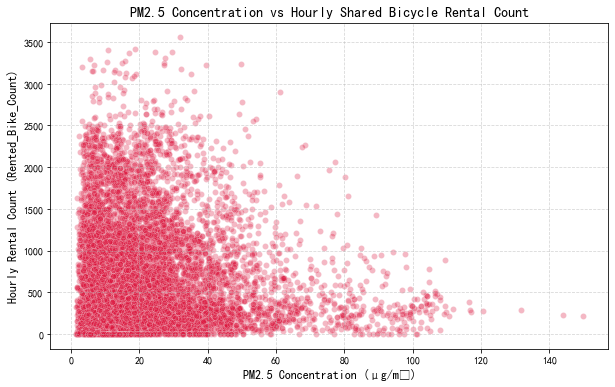

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['SimHei'] 
plt.rcParams['axes.unicode_minus'] = False


# 图表 1：PM2.5与骑行量的散点图
plt.figure(figsize=(10, 6))
# alpha=0.3 让点变透明，方便看数据重叠的密度
sns.scatterplot(data=df_merged, x='PM2.5', y='Rented_Bike_Count', alpha=0.3, color='crimson')
'''plt.title('PM2.5 浓度与共享单车每小时骑行量的关系', fontsize=14)
plt.xlabel('PM2.5 浓度 (μg/m³)', fontsize=12)
plt.ylabel('每小时骑行量 (Rented_Bike_Count)', fontsize=12)'''
plt.title('PM2.5 Concentration vs Hourly Shared Bicycle Rental Count', fontsize=14)
plt.xlabel('PM2.5 Concentration (μg/m³)', fontsize=12)
plt.ylabel('Hourly Rental Count (Rented_Bike_Count)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig("pm25_bike_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

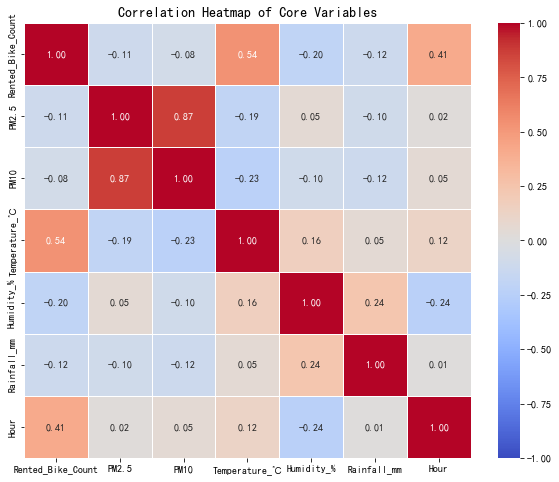

In [22]:
#  图表 2：各变量相关性热力图
plt.figure(figsize=(10, 8))
# 提取你想观察的核心变量_
corr_columns = ['Rented_Bike_Count', 'PM2.5', 'PM10', 'Temperature_℃', 'Humidity_%', 'Rainfall_mm', 'Hour']
# 计算相关系数矩阵
corr_matrix = df_merged[corr_columns].corr()

# 画热力图
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap of Core Variables', fontsize=14)
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

模型训练

In [23]:
# 1. 准备数据（选择核心数值列）
# 确保你的数据里没有 NaN 和无穷大
features = ['PM2.5', 'PM10', 'Temperature_℃', 'Humidity_%', 'Rainfall_mm', 'Hour']
df_model = df_merged[features + ['Rented_Bike_Count']].dropna()

X = df_model[features]
y = df_model['Rented_Bike_Count']

# 2. 划分训练集和测试集（80%训练，20%测试）
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 训练线性回归模型
lr = LinearRegression()
lr.fit(X_train, y_train)

# 4. 预测与评估
y_pred = lr.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred, squared=False)

print(f"模型 R²: {r2:.4f}")
print(f"模型 RMSE: {rmse:.2f}")
print("\n各变量的系数：")
for feature, coef in zip(features, lr.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"截距: {lr.intercept_:.4f}")

模型 R²: 0.4583
模型 RMSE: 475.08

各变量的系数：
PM2.5: -2.5154
PM10: 1.3739
Temperature_℃: 28.6634
Humidity_%: -5.3579
Rainfall_mm: -65.7229
Hour: 28.9302
截距: 325.9568


## Model Interpretation
The multiple linear regression model achieves R² = 0.4583. This means around 45.83% of variance in bicycle rental counts can be explained by our selected features.

Key coefficient interpretation:
- `PM2.5`: coefficient = -2.5154 → Higher PM2.5 reduces bike rental volume.
- `Temperature_℃`: coefficient = 28.6634 → Warmer temperature increases bike rentals strongly.
- `Rainfall_mm`: coefficient = -65.7229 → Rainfall has a strong negative effect on bicycle usage.
- `Hour`: coefficient = 28.9302 → Rush hours tend to raise rental demand.

### Model Limitations
1. Linear regression only captures linear relationships. The real-world relationship between air quality and bike use may be non-linear.
2. The dataset only covers 2017–2018 Seoul data; findings cannot generalize to other cities or years.
3. Some confounding variables (such as public holidays, road construction) are not fully controlled in this model.
